# DS201 – Lab 4: Encoder–Decoder và Attention cho dịch máy Anh–Việt

- Họ tên: Nguyễn Phương Nguyên
- MSSV: 24521196
- Dữ liệu: small-PhoMT 

## 0. Cài đặt và cấu hình

In [1]:
%pip install -q rouge-score sacrebleu

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


In [2]:
import hashlib, json, random, time, unicodedata, urllib.request
from collections import Counter
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from torch import nn
from torch.nn.utils.rnn import pad_sequence, pack_padded_sequence, pad_packed_sequence
from torch.utils.data import DataLoader
from rouge_score import rouge_scorer
from sacrebleu.metrics import BLEU

def seed_all(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

seed_all()
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('PyTorch:', torch.__version__, '| device:', device)
if device.type == 'cuda':
    print('GPU:', torch.cuda.get_device_name(0))

PyTorch: 2.14.1+cu130 | device: cuda
GPU: Tesla T4


In [ ]:
# Cấu hình 
cfg = dict(
    emb=256, hidden=256, layers=3,
    dropout=0.3, batch=32, lr=1e-3, teacher_ratio=0.5,
    epochs=10,
    max_words=50,
    vocab_limit=10000, min_freq=2,
    train_limit=None,  
    dev_limit=None,     
)
EVAL_BATCH = 128       

for k, v in cfg.items():
    print(f'{k:14}= {v}')

DATA = Path('data')
ART = Path('artifacts')
DATA.mkdir(exist_ok=True)
ART.mkdir(exist_ok=True)
PAD, UNK, BOS, EOS = 0, 1, 2, 3

emb           = 256
hidden        = 256
layers        = 3
dropout       = 0.3
batch         = 32
lr            = 0.001
teacher_ratio = 0.5
epochs        = 10
max_words     = 50
vocab_limit   = 10000
min_freq      = 2
train_limit   = None
dev_limit     = None


## 1. Dữ liệu small-PhoMT

In [4]:
DATA_FILES = [
    {'file': 'small-train.json',
     'url': 'https://drive.google.com/uc?export=download&id=1-eG6FeF-v__rsf77iWurddahXbyjTYh5',
     'sha256': 'f643c83f1ce3c9781eb5e03ed3ea56406abd4d877fde965d60c0a213d3906cba'},
    {'file': 'small-dev.json',
     'url': 'https://drive.google.com/uc?export=download&id=1hoTd2hFwjSeFThlPm6YpN0NW5ePXS3Jc',
     'sha256': 'fceab11b93c92167887c90f22ccc2f08c9ac8cb1c7786decc544ae90de1c23f9'},
    {'file': 'small-test.json',
     'url': 'https://drive.google.com/uc?export=download&id=1_3L25SH1_jaEfOjpmpgnfMik4N3MxSyn',
     'sha256': '1c63903af344ead37b85e2a51487e71bf44c0ceed7797b5979a9551282d83d1a'},
]

for item in DATA_FILES:
    path = DATA/item['file']
    if not path.exists():
        with urllib.request.urlopen(item['url'], timeout=90) as r:
            content = r.read()
        if hashlib.sha256(content).hexdigest() != item['sha256']:
            raise ValueError('Tải lỗi hoặc nhận về HTML: ' + item['file'])
        path.write_bytes(content)
    if hashlib.sha256(path.read_bytes()).hexdigest() != item['sha256']:
        raise ValueError('Checksum không khớp: ' + item['file'])
print('3/3 tệp khớp SHA-256')

3/3 tệp khớp SHA-256


In [5]:
def tokens(text):
    text = unicodedata.normalize('NFC', text.replace('﻿', ''))
    return text.lower().split()

raw, filtered = {}, {}
for split in ['train', 'dev', 'test']:
    raw[split] = json.loads((DATA/f'small-{split}.json').read_text(encoding='utf-8-sig'))
    filtered[split] = []
    for i, row in enumerate(raw[split]):
        src, tgt = tokens(row['english']), tokens(row['vietnamese'])
        if 1 <= len(src) <= cfg['max_words'] and 1 <= len(tgt) <= cfg['max_words']:
            filtered[split].append(dict(id=i, src=src, tgt=tgt))
    print(f"{split:5} | gốc: {len(raw[split]):6} | sau lọc: {len(filtered[split]):6}")

assert [len(filtered[s]) for s in ['train', 'dev', 'test']] == [18607, 1901, 1786]

train | gốc:  20000 | sau lọc:  18607
dev   | gốc:   2000 | sau lọc:   1901
test  | gốc:   2000 | sau lọc:   1786


## 2. Từ điển và DataLoader

In [6]:
SPECIAL = ['<pad>', '<unk>', '<bos>', '<eos>']

def make_vocab(sequences):
    freq = Counter(t for seq in sequences for t in seq)
    ranked = sorted(freq, key=lambda t: (-freq[t], t))
    keep = [t for t in ranked if freq[t] >= cfg['min_freq'] and t not in SPECIAL]
    keep = keep[:cfg['vocab_limit'] - 4]
    return {t: i for i, t in enumerate(SPECIAL + keep)}

src_vocab = make_vocab(r['src'] for r in filtered['train'])
tgt_vocab = make_vocab(r['tgt'] for r in filtered['train'])
tgt_itos = {i: t for t, i in tgt_vocab.items()}
print('Từ điển Anh:', len(src_vocab), '| Việt:', len(tgt_vocab))

def encode(seq, vocab):
    return [vocab.get(t, UNK) for t in seq]

def decode(ids):
    words = []
    for value in ids:
        i = int(value)
        if i == EOS:
            break
        if i not in (PAD, BOS):
            words.append(tgt_itos[i])
    return ' '.join(words)

def collate(rows):
    src = [torch.tensor(encode(r['src'], src_vocab) + [EOS]) for r in rows]
    tgt = [torch.tensor([BOS] + encode(r['tgt'], tgt_vocab) + [EOS]) for r in rows]
    return dict(
        src=pad_sequence(src, batch_first=True, padding_value=PAD),
        lengths=torch.tensor([len(x) for x in src]),
        tgt=pad_sequence(tgt, batch_first=True, padding_value=PAD),
        refs=[' '.join(r['tgt']) for r in rows],
        ids=[r['id'] for r in rows],
    )

def choose(rows, limit):
    if limit is None or len(rows) <= limit:
        return rows
    ids = np.random.default_rng(42).permutation(len(rows))[:limit]
    return [rows[int(i)] for i in ids]

train_rows = choose(filtered['train'], cfg['train_limit'])
dev_rows = choose(filtered['dev'], cfg['dev_limit'])
test_rows = filtered['test']
print('train/dev/test:', len(train_rows), len(dev_rows), len(test_rows))

def loader(rows, shuffle=False, batch_size=None):
    return DataLoader(rows, batch_size=batch_size or cfg['batch'], shuffle=shuffle,
                      collate_fn=collate, generator=torch.Generator().manual_seed(42))

Từ điển Anh: 8943 | Việt: 4003
train/dev/test: 18607 1901 1786


## 3. Mô hình
- **Encoder**: Embedding → LSTM 3 lớp. Trả về memory [B, S, H] cho attention và (h, c) [3, B, H] để khởi tạo decoder.
- **Attention**:
  - Bahdanau (additive): $e_{t,i} = v^\top \tanh(W_q s_{t-1} + W_k h_i)$
  - Luong (global, general): $e_{t,i} = s_t^\top W h_i$
- **Decoder**:
  - `none`: LSTM chỉ nhận embedding của token trước.
  - `bahdanau`: query là trạng thái lớp trên cùng ở bước trước $s_{t-1}$; context $c_t$ được nối với embedding trước khi vào LSTM.
  - `luong`: LSTM cập nhật trước, dùng $s_t$ làm query; $\tilde{h}_t = \tanh(W_c[s_t; c_t])$ dùng để dự đoán và được đưa vào bước sau (input feeding).

In [7]:
class Encoder(nn.Module):
    def __init__(self, vocab_size, emb, hidden, layers, dropout):
        super().__init__()
        self.emb = nn.Embedding(vocab_size, emb, padding_idx=PAD)
        self.drop = nn.Dropout(dropout)
        self.rnn = nn.LSTM(emb, hidden, layers, batch_first=True,
                           dropout=dropout if layers > 1 else 0.0)

    def forward(self, src, lengths):
        packed = pack_padded_sequence(self.drop(self.emb(src)), lengths.cpu(),
                                      batch_first=True, enforce_sorted=False)
        packed_out, state = self.rnn(packed)
        memory, _ = pad_packed_sequence(packed_out, batch_first=True,
                                        total_length=src.size(1))
        return memory, state


class Attention(nn.Module):
    def __init__(self, hidden, mode):
        super().__init__()
        self.mode = mode
        if mode == 'bahdanau':
            self.Wq = nn.Linear(hidden, hidden, bias=False)
            self.Wk = nn.Linear(hidden, hidden, bias=False)
            self.v = nn.Linear(hidden, 1, bias=False)
        elif mode == 'luong':
            self.W = nn.Linear(hidden, hidden, bias=False)
        else:
            raise ValueError(mode)

    def forward(self, query, memory, mask):
        if self.mode == 'bahdanau':
            energy = torch.tanh(self.Wq(query).unsqueeze(1) + self.Wk(memory))
            scores = self.v(energy).squeeze(-1)
        else:
            scores = torch.bmm(self.W(memory), query.unsqueeze(2)).squeeze(2)
        scores = scores.masked_fill(~mask, float('-inf'))
        weights = torch.softmax(scores, dim=-1)
        context = torch.bmm(weights.unsqueeze(1), memory).squeeze(1)
        return context, weights


class Decoder(nn.Module):
    def __init__(self, vocab_size, mode, emb, hidden, layers, dropout):
        super().__init__()
        self.mode = mode
        self.emb = nn.Embedding(vocab_size, emb, padding_idx=PAD)
        self.drop = nn.Dropout(dropout)
        width = emb if mode == 'none' else emb + hidden
        self.rnn = nn.LSTM(width, hidden, layers, batch_first=True,
                           dropout=dropout if layers > 1 else 0.0)
        if mode != 'none':
            self.attn = Attention(hidden, mode)
            self.fuse = nn.Linear(2 * hidden, hidden)
        self.head = nn.Linear(hidden, vocab_size)

    def step(self, token, state, memory, mask, feeding):
        embedded = self.drop(self.emb(token))
        weights = None
        if self.mode == 'bahdanau':
            context, weights = self.attn(state[0][-1], memory, mask)
            rnn_input = torch.cat([embedded, context], dim=-1)
        elif self.mode == 'luong':
            rnn_input = torch.cat([embedded, feeding], dim=-1)
        else:
            rnn_input = embedded
        out, state = self.rnn(rnn_input.unsqueeze(1), state)
        query = out[:, 0]
        if self.mode == 'luong':
            context, weights = self.attn(query, memory, mask)
        if self.mode != 'none':
            feeding = torch.tanh(self.fuse(torch.cat([query, context], -1)))
            query = feeding
        logits = self.head(self.drop(query))
        return logits, state, feeding, weights


class Seq2Seq(nn.Module):
    def __init__(self, mode, src_size, tgt_size, **kwargs):
        super().__init__()
        self.mode = mode
        self.encoder = Encoder(src_size, **kwargs)
        self.decoder = Decoder(tgt_size, mode, **kwargs)
        self.hidden = kwargs['hidden']

    def forward(self, src, lengths, tgt, teacher_ratio=0.5):
        memory, state = self.encoder(src, lengths)
        mask = src != PAD
        token = tgt[:, 0]
        feeding = memory.new_zeros(src.size(0), self.hidden)
        logits = []
        for t in range(1, tgt.size(1)):
            step, state, feeding, _ = self.decoder.step(token, state, memory, mask, feeding)
            logits.append(step)
            coin = torch.rand(src.size(0), device=src.device)
            predicted = step.argmax(-1).detach()
            token = torch.where(coin < teacher_ratio, tgt[:, t], predicted)
        return torch.stack(logits, dim=1)


model_cfg = {k: cfg[k] for k in ['emb', 'hidden', 'layers', 'dropout']}

def make_seq2seq(mode):
    return Seq2Seq(mode, len(src_vocab), len(tgt_vocab), **model_cfg).to(device)

def count_params(model):
    return sum(p.numel() for p in model.parameters())

In [ ]:
# Kiểm tra: shape đầu ra và mask PAD
b = collate(train_rows[:4])
src, tgt = b['src'].to(device), b['tgt'].to(device)
for mode in ['none', 'bahdanau', 'luong']:
    seed_all()
    m = make_seq2seq(mode).eval()
    with torch.no_grad():
        out1 = m(src, b['lengths'], tgt, teacher_ratio=1.0)
        out2 = m(nn.functional.pad(src, (0, 7)), b['lengths'], tgt, teacher_ratio=1.0)
    assert out1.shape[:2] == tgt[:, 1:].shape
    torch.testing.assert_close(out1, out2, atol=1e-5, rtol=1e-4)
    print(f'{mode:9} | logits {tuple(out1.shape)} | params {count_params(m):,} | mask OK')
del m

none      | logits (4, 30, 4003) | params 7,500,963 | mask OK
bahdanau  | logits (4, 30, 4003) | params 8,025,763 | mask OK
luong     | logits (4, 30, 4003) | params 7,959,971 | mask OK


## 4. Giải mã greedy, ROUGE-L và vòng huấn luyện

- `generate` chỉ nhận câu nguồn, sinh bằng argmax đến khi gặp `<eos>` hoặc hết 51 bước.
- ROUGE-L F1 trung bình theo câu, dùng tokenizer giữ dấu tiếng Việt, không stemming. BLEU (SacreBLEU) in thêm để tham khảo.
- Loss bỏ qua PAD, gradient clipping 1.0. Sau mỗi epoch chấm dev; giữ checkpoint có ROUGE-L dev cao nhất (bằng nhau thì lấy dev-NLL thấp hơn).

In [9]:
@torch.no_grad()
def generate(model, src, lengths, max_steps):
    model.eval()
    memory, state = model.encoder(src, lengths)
    mask = src != PAD
    token = torch.full((src.size(0),), BOS, device=src.device)
    feeding = memory.new_zeros(src.size(0), model.hidden)
    finished = torch.zeros(src.size(0), dtype=torch.bool, device=src.device)
    outputs, all_weights = [], []
    for _ in range(max_steps):
        logits, state, feeding, weights = model.decoder.step(token, state, memory, mask, feeding)
        logits[:, [PAD, BOS]] = float('-inf')
        token = logits.argmax(-1)
        token = torch.where(finished, torch.full_like(token, EOS), token)
        outputs.append(token)
        if weights is not None:
            all_weights.append(weights)
        finished = finished | (token == EOS)
        if bool(finished.all()):
            break
    ids = torch.stack(outputs, dim=1)
    weights = torch.stack(all_weights, dim=1) if all_weights else None
    return ids, weights


class UnicodeTokens:
    def tokenize(self, text):
        return tokens(text)

rouge = rouge_scorer.RougeScorer(['rougeL'], use_stemmer=False, tokenizer=UnicodeTokens())

def translation_metrics(hyps, refs):
    scores = [rouge.score(r, h)['rougeL'] for h, r in zip(hyps, refs)]
    bleu = BLEU(tokenize='none', lowercase=False).corpus_score(hyps, [refs])
    return dict(rougeL_f1=float(np.mean([s.fmeasure for s in scores])),
                rougeL_p=float(np.mean([s.precision for s in scores])),
                rougeL_r=float(np.mean([s.recall for s in scores])),
                bleu=bleu.score,
                per_sentence=[s.fmeasure for s in scores])


@torch.no_grad()
def evaluate(model, rows):
    model.eval()
    hyps, refs = [], []
    nll, count = 0.0, 0
    for b in loader(rows, batch_size=EVAL_BATCH):
        src, tgt = b['src'].to(device), b['tgt'].to(device)
        target = tgt[:, 1:]
        logits = model(src, b['lengths'], tgt, teacher_ratio=1.0)
        nll += nn.functional.cross_entropy(logits.reshape(-1, len(tgt_vocab)), target.reshape(-1),
                                           ignore_index=PAD, reduction='sum').item()
        count += int((target != PAD).sum())
        generated, _ = generate(model, src, b['lengths'], cfg['max_words'] + 1)
        hyps.extend(decode(r) for r in generated.cpu())
        refs.extend(b['refs'])
    m = translation_metrics(hyps, refs)
    m['nll'] = nll / count
    m['hyps'] = hyps
    return m


criterion = nn.CrossEntropyLoss(ignore_index=PAD)

def train_epoch(model, train_loader, optimizer):
    model.train()
    loss_total, tokens_total = 0.0, 0
    for b in train_loader:
        src, tgt = b['src'].to(device), b['tgt'].to(device)
        optimizer.zero_grad(set_to_none=True)
        logits = model(src, b['lengths'], tgt, cfg['teacher_ratio'])
        gold = tgt[:, 1:]
        loss = criterion(logits.reshape(-1, len(tgt_vocab)), gold.reshape(-1))
        loss.backward()
        nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        optimizer.step()
        n = int((gold != PAD).sum())
        loss_total += loss.item() * n
        tokens_total += n
    return loss_total / tokens_total


def fit(model, name):
    optimizer = torch.optim.Adam(model.parameters(), lr=cfg['lr'])
    train_loader = loader(train_rows, shuffle=True)
    best_key, best_state, best_epoch = (-1.0, float('-inf')), None, 0
    history = []
    for epoch in range(1, cfg['epochs'] + 1):
        seed_all(42 + epoch)
        start = time.perf_counter()
        train_loss = train_epoch(model, train_loader, optimizer)
        if device.type == 'cuda':
            torch.cuda.synchronize()
        seconds = time.perf_counter() - start
        dev = evaluate(model, dev_rows)
        key = (dev['rougeL_f1'], -dev['nll'])
        if key > best_key:
            best_key, best_epoch = key, epoch
            best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
        history.append(dict(epoch=epoch, train_loss=train_loss, dev_nll=dev['nll'],
                            dev_rougeL=dev['rougeL_f1'], dev_bleu=dev['bleu'], seconds=seconds))
        print(f"[{name}] epoch {epoch:2}/{cfg['epochs']} | train_loss {train_loss:.4f} | "
              f"dev_nll {dev['nll']:.4f} | dev ROUGE-L {dev['rougeL_f1']:.4f} | "
              f"BLEU {dev['bleu']:.2f} | {seconds:.1f}s")
    model.load_state_dict(best_state)
    model.eval()
    torch.save(best_state, ART/f'{name}.pt')
    print(f'Checkpoint tốt nhất: epoch {best_epoch}')
    return pd.DataFrame(history), best_epoch

In [10]:
# Các hàm dùng chung cho phần báo cáo của từng bài
results = {}

def plot_history(history, name, title):
    fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
    axes[0].plot(history.epoch, history.train_loss, marker='o', label='train loss')
    axes[0].plot(history.epoch, history.dev_nll, marker='o', label='dev NLL')
    axes[0].set_title(f'{title}: loss')
    axes[1].plot(history.epoch, history.dev_rougeL, marker='o', color='tab:green')
    axes[1].set_title(f'{title}: ROUGE-L F1 trên dev')
    for ax in axes:
        ax.set_xlabel('epoch')
        ax.grid(alpha=0.3)
    axes[0].legend()
    fig.tight_layout()
    fig.savefig(ART/f'curve_{name}.png', dpi=150)
    plt.show()

def run_test(model, name, history, best_epoch):
    dev = evaluate(model, dev_rows)
    test = evaluate(model, test_rows)
    results[name] = dict(model=model, history=history, best_epoch=best_epoch, dev=dev, test=test)
    print(f"ROUGE-L test: F1 {test['rougeL_f1']:.4f} | P {test['rougeL_p']:.4f} | "
          f"R {test['rougeL_r']:.4f} | BLEU {test['bleu']:.2f}")
    print(f"ROUGE-L dev (checkpoint epoch {best_epoch}): {dev['rougeL_f1']:.4f}")
    pd.DataFrame(dict(id=[r['id'] for r in test_rows], src=[' '.join(r['src']) for r in test_rows],
                      ref=[' '.join(r['tgt']) for r in test_rows], hyp=test['hyps'],
                      rougeL=test['per_sentence'])).to_csv(ART/f'test_predictions_{name}.csv', index=False)

def pick_samples(name, max_len=25):
    # Chọn 3 câu test (độ dài nguồn <= max_len): ROUGE-L cao nhất, trung vị, thấp nhất
    scores = results[name]['test']['per_sentence']
    idx = [i for i, r in enumerate(test_rows) if len(r['src']) <= max_len]
    idx.sort(key=lambda i: scores[i])
    return [idx[-1], idx[len(idx) // 2], idx[0]]

def show_samples(name, indices):
    test = results[name]['test']
    for label, i in zip(['cao nhất', 'trung vị', 'thấp nhất'], indices):
        r = test_rows[i]
        print(f"--- Câu test #{r['id']} (ROUGE-L {test['per_sentence'][i]:.3f}, {label}) ---")
        print('EN :', ' '.join(r['src']))
        print('REF:', ' '.join(r['tgt']))
        print('HYP:', test['hyps'][i])
        print()

def plot_attention(model, i, name, k):
    row = test_rows[i]
    b = collate([row])
    ids, weights = generate(model, b['src'].to(device), b['lengths'], cfg['max_words'] + 1)
    ids = ids[0].cpu().tolist()
    stop = ids.index(EOS) + 1 if EOS in ids else len(ids)
    matrix = weights[0, :stop, :b['lengths'][0]].cpu().numpy()
    assert np.allclose(matrix.sum(-1), 1.0, atol=1e-5)
    x_labels = row['src'] + ['<eos>']
    y_labels = [tgt_itos[t] for t in ids[:stop]]
    fig, ax = plt.subplots(figsize=(max(6, 0.4 * len(x_labels)), max(4, 0.32 * len(y_labels))))
    im = ax.imshow(matrix, cmap='Blues', aspect='auto', vmin=0, vmax=1)
    ax.set_xticks(range(len(x_labels)))
    ax.set_xticklabels(x_labels, rotation=60, ha='right')
    ax.set_yticks(range(len(y_labels)))
    ax.set_yticklabels(y_labels)
    ax.set_xlabel('Token nguồn (EN)')
    ax.set_ylabel('Token sinh ra (VI)')
    ax.set_title(f"{name} – câu test #{row['id']}")
    fig.colorbar(im, ax=ax)
    fig.tight_layout()
    fig.savefig(ART/f'attention_{name}_{k}.png', dpi=150)
    plt.show()

## Bài 1. Encoder–Decoder LSTM (không attention)

Encoder 3 lớp LSTM nén câu nguồn thành trạng thái cuối `(h, c)`, dùng làm trạng thái khởi đầu cho decoder 3 lớp LSTM.

In [11]:
seed_all()
model_none = make_seq2seq('none')
print('Số tham số:', f'{count_params(model_none):,}')
history_none, best_epoch_none = fit(model_none, 'none')

Số tham số: 7,500,963


[none] epoch  1/10 | train_loss 6.0257 | dev_nll 5.9175 | dev ROUGE-L 0.1280 | BLEU 0.06 | 91.2s


[none] epoch  2/10 | train_loss 5.7262 | dev_nll 5.6206 | dev ROUGE-L 0.1561 | BLEU 0.54 | 87.0s


[none] epoch  3/10 | train_loss 5.5368 | dev_nll 5.4316 | dev ROUGE-L 0.1902 | BLEU 1.18 | 85.4s


[none] epoch  4/10 | train_loss 5.3961 | dev_nll 5.2940 | dev ROUGE-L 0.1927 | BLEU 1.29 | 84.0s


[none] epoch  5/10 | train_loss 5.2825 | dev_nll 5.1736 | dev ROUGE-L 0.2017 | BLEU 1.34 | 84.9s


[none] epoch  6/10 | train_loss 5.1864 | dev_nll 5.0822 | dev ROUGE-L 0.2139 | BLEU 1.73 | 89.8s


[none] epoch  7/10 | train_loss 5.1044 | dev_nll 5.0031 | dev ROUGE-L 0.2173 | BLEU 1.91 | 87.3s


[none] epoch  8/10 | train_loss 5.0285 | dev_nll 4.9365 | dev ROUGE-L 0.2208 | BLEU 2.07 | 85.0s


[none] epoch  9/10 | train_loss 4.9619 | dev_nll 4.8739 | dev ROUGE-L 0.2267 | BLEU 2.16 | 84.7s


[none] epoch 10/10 | train_loss 4.9011 | dev_nll 4.8273 | dev ROUGE-L 0.2298 | BLEU 2.34 | 84.6s
Checkpoint tốt nhất: epoch 10


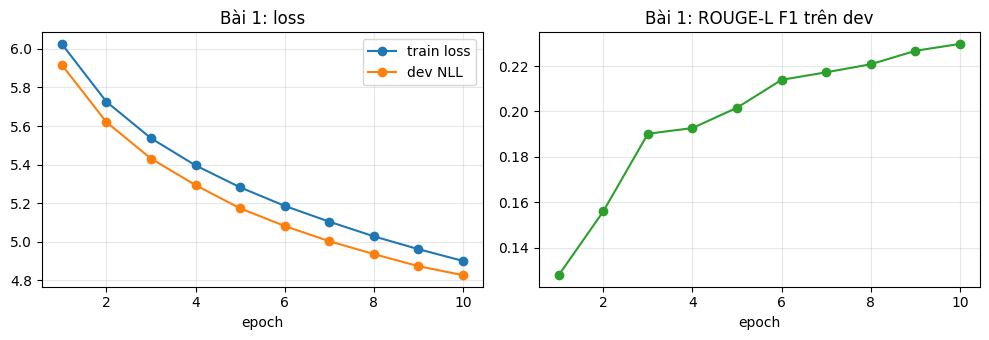

In [12]:
plot_history(history_none, 'none', 'Bài 1')

In [13]:
run_test(model_none, 'none', history_none, best_epoch_none)

ROUGE-L test: F1 0.2346 | P 0.2608 | R 0.2161 | BLEU 2.61
ROUGE-L dev (checkpoint epoch 10): 0.2298


In [14]:
samples_none = pick_samples('none')
show_samples('none', samples_none)

--- Câu test #822 (ROUGE-L 1.000, cao nhất) ---
EN : ( applause )
REF: ( vỗ tay )
HYP: ( vỗ tay )

--- Câu test #1334 (ROUGE-L 0.235, trung vị) ---
EN : stick with the people you know .
REF: " hãy chỉ gắn bó với những người bạn biết .
HYP: để để bạn bạn bạn .

--- Câu test #58 (ROUGE-L 0.000, thấp nhất) ---
EN : lifetime employment for public employees abolished from today
REF: bãi bỏ viên chức suốt đời cho cán bộ nhà nước từ hôm nay
HYP: hãy bắt đầu của <unk> <unk> <unk> <unk> <unk> .



### Nhận xét Bài 1

- Train loss giảm đều từ 6.03 xuống 4.90, dev NLL từ 5.92 xuống 4.83; ROUGE-L dev tăng từ 0.128 lên 0.230. Checkpoint tốt nhất ở epoch 10 và cả hai đường vẫn chưa đi ngang, nên mô hình chưa hội tụ sau 10 epoch.
- ROUGE-L F1 trên test là 0.2346 (P = 0.261, R = 0.216), BLEU 2.61. Recall thấp hơn precision và câu sinh ra ngắn hơn câu tham chiếu (trung bình khoảng 0.84 lần), tức là mô hình hay bỏ sót nội dung.
- Ba câu mẫu:
  - #822 "( applause )" dịch đúng hoàn toàn "( vỗ tay )". Đây là câu rất ngắn và xuất hiện nhiều trong dữ liệu TED nên mô hình học thuộc được.
  - #1334 (trung vị): "để để bạn bạn bạn ." bị lặp từ, gần như mất nghĩa. Điểm 0.235 chủ yếu nhờ trùng "bạn" và dấu chấm, cho thấy ROUGE-L ở mức chữ có thể đánh giá cao những câu không dùng được.
  - #58 (thấp nhất): câu tiêu đề báo nhiều từ hiếm ("lifetime employment", "abolished") nên đầu ra gồm "hãy bắt đầu của" và một chuỗi `<unk>`.
- Lỗi chính là lặp từ, sinh `<unk>` và bỏ sót thông tin ở câu dài. Encoder phải nén cả câu nguồn vào trạng thái cuối (h, c) có kích thước cố định, nên câu càng dài thì decoder càng thiếu thông tin.

## Bài 2. Encoder–Decoder LSTM với Bahdanau attention

Cùng cấu hình như Bài 1, decoder thêm attention cộng theo Bahdanau et al. (2015). Ở mỗi bước, trạng thái lớp trên cùng của bước trước được dùng làm query để tính context, context được nối với embedding trước khi đưa vào LSTM.

In [15]:
seed_all()
model_bahdanau = make_seq2seq('bahdanau')
print('Số tham số:', f'{count_params(model_bahdanau):,}')
history_bahdanau, best_epoch_bahdanau = fit(model_bahdanau, 'bahdanau')

Số tham số: 8,025,763


[bahdanau] epoch  1/10 | train_loss 6.0413 | dev_nll 5.9062 | dev ROUGE-L 0.1413 | BLEU 0.17 | 145.1s


[bahdanau] epoch  2/10 | train_loss 5.6456 | dev_nll 5.4816 | dev ROUGE-L 0.1985 | BLEU 1.17 | 141.5s


[bahdanau] epoch  3/10 | train_loss 5.3636 | dev_nll 5.2202 | dev ROUGE-L 0.2175 | BLEU 1.64 | 142.4s


[bahdanau] epoch  4/10 | train_loss 5.1682 | dev_nll 5.0422 | dev ROUGE-L 0.2445 | BLEU 2.38 | 144.6s


[bahdanau] epoch  5/10 | train_loss 4.9980 | dev_nll 4.8937 | dev ROUGE-L 0.2525 | BLEU 2.68 | 151.1s


[bahdanau] epoch  6/10 | train_loss 4.8640 | dev_nll 4.7743 | dev ROUGE-L 0.2721 | BLEU 3.48 | 148.4s


[bahdanau] epoch  7/10 | train_loss 4.7457 | dev_nll 4.6804 | dev ROUGE-L 0.2755 | BLEU 3.66 | 148.3s


[bahdanau] epoch  8/10 | train_loss 4.6416 | dev_nll 4.6027 | dev ROUGE-L 0.2856 | BLEU 3.96 | 148.6s


[bahdanau] epoch  9/10 | train_loss 4.5577 | dev_nll 4.5434 | dev ROUGE-L 0.2948 | BLEU 4.48 | 151.7s


[bahdanau] epoch 10/10 | train_loss 4.4777 | dev_nll 4.4868 | dev ROUGE-L 0.2975 | BLEU 4.56 | 149.0s
Checkpoint tốt nhất: epoch 10


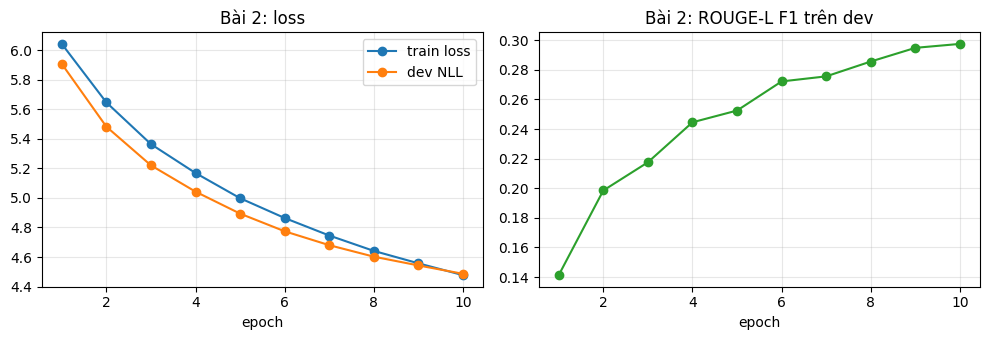

In [16]:
plot_history(history_bahdanau, 'bahdanau', 'Bài 2')

In [17]:
run_test(model_bahdanau, 'bahdanau', history_bahdanau, best_epoch_bahdanau)

ROUGE-L test: F1 0.3138 | P 0.3403 | R 0.2957 | BLEU 5.83
ROUGE-L dev (checkpoint epoch 10): 0.2975


In [18]:
samples_bahdanau = pick_samples('bahdanau')
show_samples('bahdanau', samples_bahdanau)

--- Câu test #822 (ROUGE-L 1.000, cao nhất) ---
EN : ( applause )
REF: ( vỗ tay )
HYP: ( vỗ tay )

--- Câu test #1412 (ROUGE-L 0.318, trung vị) ---
EN : we 've seen how distributed networks , big data and information can transform society .
REF: nhờ mạng phân phối , các thông tin và dữ liệu lớn có thể làm biến đổi xã hội .
HYP: chúng ta đã thấy những công nghệ lớn , , dữ liệu , và dữ liệu có thể tạo ra các hệ thống .

--- Câu test #75 (ROUGE-L 0.000, thấp nhất) ---
EN : dismantling saigon 's binh trieu tollgates finished
REF: đã hoàn thành việc tháo dỡ các trạm thu phí bình triệu ở sài gòn
HYP: <unk> <unk> <unk> <unk> <unk> <unk> .



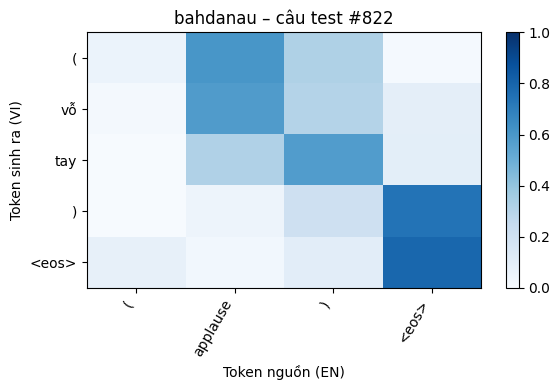

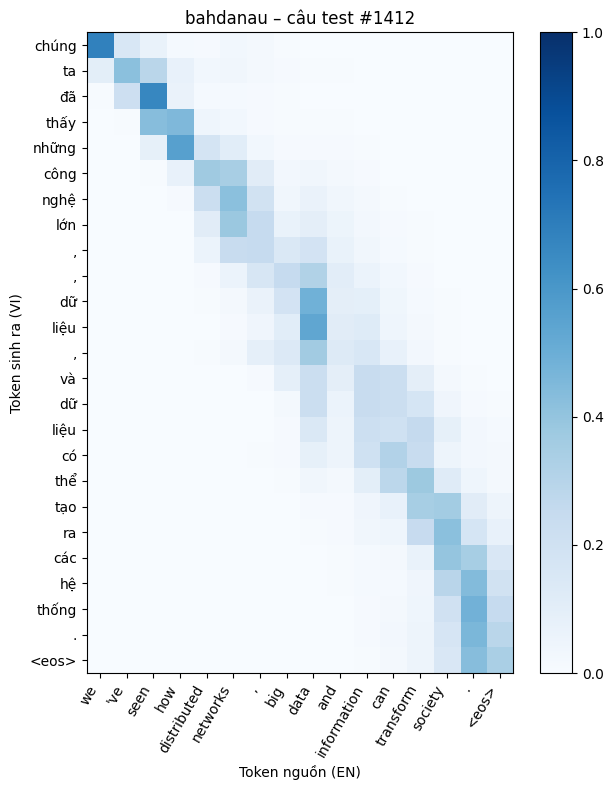

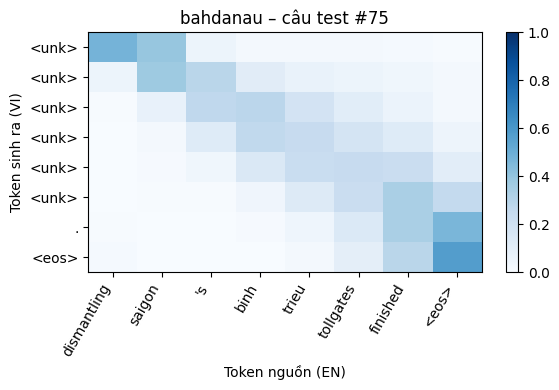

In [19]:
# Heatmap attention của 3 câu mẫu
for k, i in enumerate(samples_bahdanau, 1):
    plot_attention(model_bahdanau, i, 'bahdanau', k)

### Nhận xét Bài 2

- Loss giảm nhanh hơn Bài 1 (6.04 xuống 4.48), ROUGE-L dev tăng từ 0.141 lên 0.298 và vẫn còn tăng ở epoch 10.
- ROUGE-L F1 test là 0.3138 (P = 0.340, R = 0.296), BLEU 5.83, cao hơn Bài 1 khoảng 0.079 ROUGE-L và gấp đôi BLEU.
- Ba câu mẫu:
  - #822 dịch đúng giống Bài 1.
  - #1412 (trung vị): mô hình dịch được phần đầu "chúng ta đã thấy" (we 've seen), "dữ liệu" (data), "có thể" (can), nhưng "transform society" thành "tạo ra các hệ thống" và vẫn còn lặp "dữ liệu". Câu tham chiếu dịch thoáng ("nhờ mạng phân phối…") nên ROUGE-L (0.318) đánh giá thấp hơn chất lượng thực tế một chút. Bài 1 cho câu này chỉ được 0.143 vì lặp "những", "và" nhiều lần.
  - #75 (thấp nhất): câu tiêu đề có tên riêng (saigon, binh trieu, tollgates) nằm ngoài từ điển nên đầu ra toàn `<unk>`. Attention không giúp được khi từ cần sinh không có trong từ điển.
- Heatmap:
  - Câu #1412: trọng số chạy gần theo đường chéo vì trật tự từ Anh–Việt ở câu này khá giống nhau. "chúng ta đã" chú ý vào "we 've", "thấy" vào "seen / how", "dữ liệu" vào "data" (khoảng 0.5–0.6), "có thể" vào "can", "tạo ra" vào "transform / society", dấu chấm và `<eos>` vào ". / <eos>". Attention là phân phối mềm: mỗi từ thường rải trên 2–3 token nguồn chứ không nhọn tuyệt đối.
  - Câu #75: attention vẫn trượt dần theo câu nguồn, nhưng đầu ra toàn `<unk>`, cho thấy căn chỉnh đúng chưa đủ khi từ vựng không có.

## Bài 3. Encoder–Decoder LSTM với Luong attention

Cùng cấu hình, decoder dùng global attention dạng general theo Luong et al. (2015): LSTM cập nhật trước, trạng thái mới $s_t$ làm query, vector $\tilde{h}_t = \tanh(W_c[s_t; c_t])$ dùng để dự đoán và đưa vào bước sau (input feeding).

In [20]:
seed_all()
model_luong = make_seq2seq('luong')
print('Số tham số:', f'{count_params(model_luong):,}')
history_luong, best_epoch_luong = fit(model_luong, 'luong')

Số tham số: 7,959,971


[luong] epoch  1/10 | train_loss 6.0734 | dev_nll 5.9704 | dev ROUGE-L 0.1301 | BLEU 0.11 | 139.7s


[luong] epoch  2/10 | train_loss 5.7382 | dev_nll 5.6299 | dev ROUGE-L 0.1692 | BLEU 0.81 | 141.0s


[luong] epoch  3/10 | train_loss 5.5026 | dev_nll 5.3820 | dev ROUGE-L 0.1936 | BLEU 1.20 | 144.1s


[luong] epoch  4/10 | train_loss 5.2998 | dev_nll 5.1708 | dev ROUGE-L 0.2208 | BLEU 1.77 | 152.2s


[luong] epoch  5/10 | train_loss 5.1162 | dev_nll 4.9919 | dev ROUGE-L 0.2355 | BLEU 2.26 | 150.4s


[luong] epoch  6/10 | train_loss 4.9604 | dev_nll 4.8394 | dev ROUGE-L 0.2503 | BLEU 2.88 | 148.8s


[luong] epoch  7/10 | train_loss 4.8296 | dev_nll 4.7293 | dev ROUGE-L 0.2664 | BLEU 3.46 | 148.1s


[luong] epoch  8/10 | train_loss 4.7166 | dev_nll 4.6340 | dev ROUGE-L 0.2775 | BLEU 3.91 | 148.3s


[luong] epoch  9/10 | train_loss 4.6231 | dev_nll 4.5666 | dev ROUGE-L 0.2865 | BLEU 4.20 | 149.9s


[luong] epoch 10/10 | train_loss 4.5282 | dev_nll 4.4988 | dev ROUGE-L 0.2905 | BLEU 4.49 | 151.6s
Checkpoint tốt nhất: epoch 10


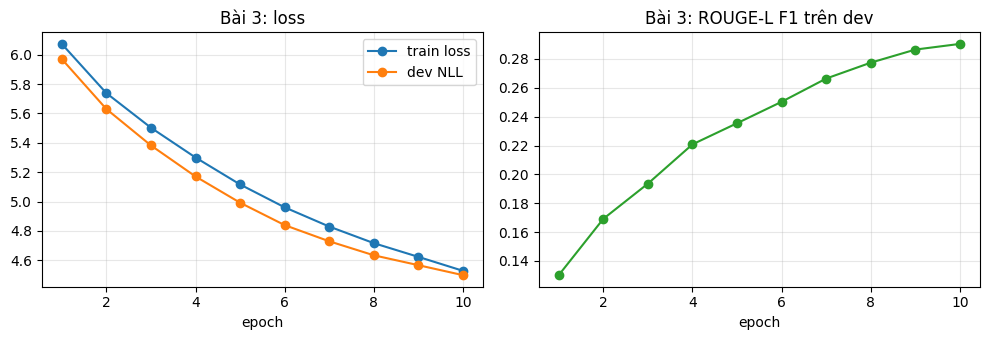

In [21]:
plot_history(history_luong, 'luong', 'Bài 3')

In [22]:
run_test(model_luong, 'luong', history_luong, best_epoch_luong)

ROUGE-L test: F1 0.3054 | P 0.3315 | R 0.2873 | BLEU 5.52
ROUGE-L dev (checkpoint epoch 10): 0.2905


In [23]:
samples_luong = pick_samples('luong')
show_samples('luong', samples_luong)

--- Câu test #1991 (ROUGE-L 1.000, cao nhất) ---
EN : just five days .
REF: chỉ 5 ngày .
HYP: chỉ 5 ngày .

--- Câu test #1533 (ROUGE-L 0.308, trung vị) ---
EN : would you deserve to be killed ?
REF: nào bạn xứng đáng để bị giết ?
HYP: bạn sẽ phải được ?

--- Câu test #58 (ROUGE-L 0.000, thấp nhất) ---
EN : lifetime employment for public employees abolished from today
REF: bãi bỏ viên chức suốt đời cho cán bộ nhà nước từ hôm nay
HYP: những người đã bắt đầu học những những học .



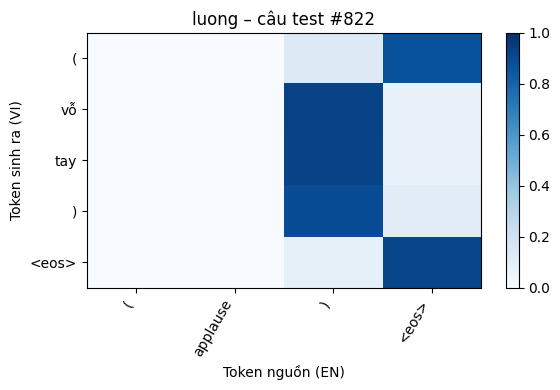

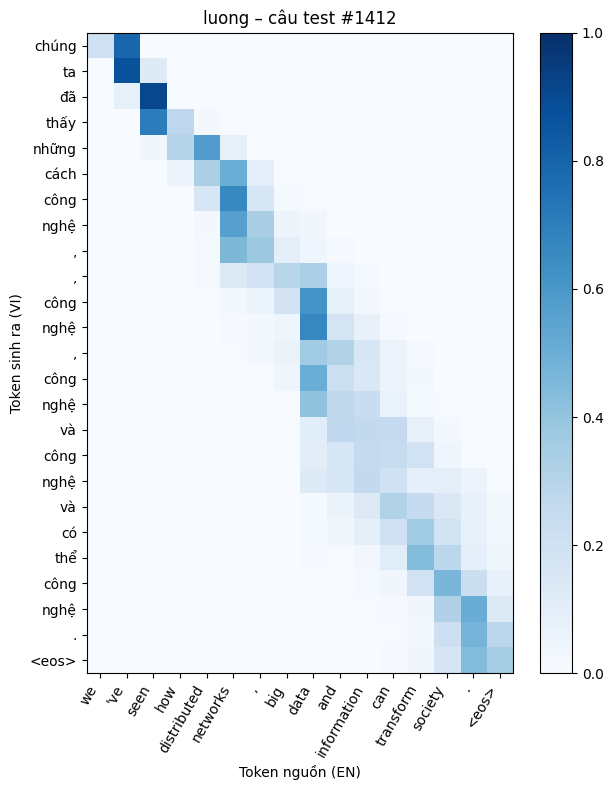

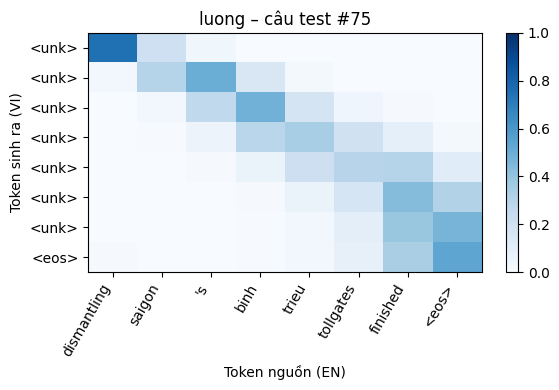

In [24]:
# Heatmap Luong trên cùng 3 câu đã chọn cho Bahdanau để so sánh hai kiểu attention
for k, i in enumerate(samples_bahdanau, 1):
    plot_attention(model_luong, i, 'luong', k)

### Nhận xét Bài 3

- Loss giảm từ 6.07 xuống 4.53, ROUGE-L dev tăng từ 0.130 lên 0.291 và vẫn còn tăng ở epoch 10.
- ROUGE-L F1 test là 0.3054 (P = 0.332, R = 0.287), BLEU 5.52, cao hơn Bài 1 khoảng 0.071 ROUGE-L và thấp hơn Bài 2 khoảng 0.008.
- Ba câu mẫu:
  - #1991 "just five days ." dịch đúng hoàn toàn "chỉ 5 ngày .".
  - #1533 (trung vị): "bạn sẽ phải được ?" mất động từ chính "killed" nên sai nghĩa, dù vẫn giữ được chủ ngữ "bạn" và dấu hỏi.
  - #58 (thấp nhất): sinh "những người đã bắt đầu học những những học ." lặp từ và không liên quan đến câu nguồn (cũng là câu thấp nhất của Bài 1).
- Heatmap:
  - Câu #1412: attention Luong cũng đi theo đường chéo, và ở đầu câu nhọn hơn Bahdanau ("chúng ta đã" tập trung khoảng 0.8–0.9 vào "'ve / seen").
  - Tuy vậy, mô hình lặp "công nghệ" 5 lần trong khi attention vẫn dịch dần từ networks → data → information → society. Nghĩa là attention có thể chỉ đúng vị trí trong câu nguồn, nhưng decoder vẫn sinh từ phổ biến thay vì từ đúng.

## Bảng tổng hợp kết quả 

In [25]:
names = {'none': 'Bài 1. Không attention', 'bahdanau': 'Bài 2. Bahdanau', 'luong': 'Bài 3. Luong'}
summary = pd.DataFrame([dict(
    **{'Mô hình': names[n]},
    **{'ROUGE-L dev': round(r['dev']['rougeL_f1'], 4),
       'ROUGE-L test': round(r['test']['rougeL_f1'], 4),
       'BLEU test': round(r['test']['bleu'], 2),
       'Số tham số': f"{count_params(r['model']):,}",
       'Giây/epoch': round(r['history'].seconds.mean(), 1),
       'Epoch tốt nhất': r['best_epoch']})
    for n, r in results.items()])
summary.to_csv(ART/'summary_results.csv', index=False)
summary

,Mô hình,ROUGE-L dev,ROUGE-L test,BLEU test,Số tham số,Giây/epoch,Epoch tốt nhất
0,Bài 1. Không attention,0.2298,0.2346,2.61,"7,500,963",86.4,10
1,Bài 2. Bahdanau,0.2975,0.3138,5.83,"8,025,763",147.1,10
2,Bài 3. Luong,0.2905,0.3054,5.52,"7,959,971",147.4,10


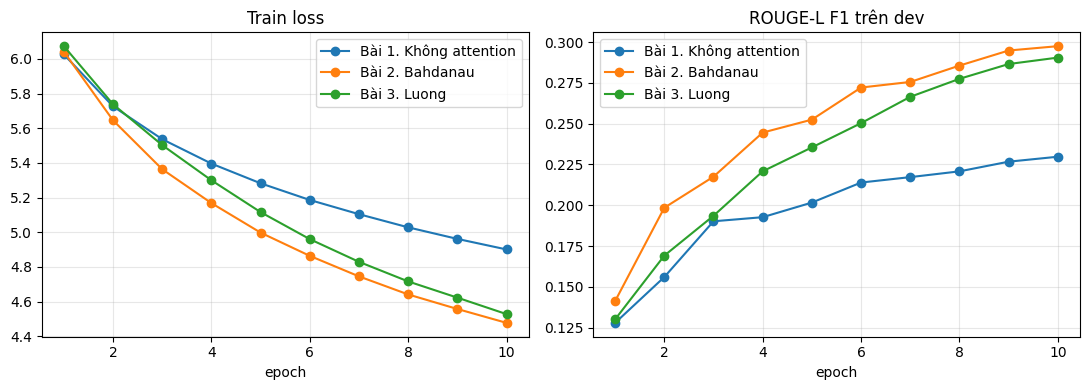

In [26]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for n, r in results.items():
    h = r['history']
    axes[0].plot(h.epoch, h.train_loss, marker='o', label=names[n])
    axes[1].plot(h.epoch, h.dev_rougeL, marker='o', label=names[n])
axes[0].set_title('Train loss')
axes[1].set_title('ROUGE-L F1 trên dev')
for ax in axes:
    ax.set_xlabel('epoch')
    ax.grid(alpha=0.3)
    ax.legend()
fig.tight_layout()
fig.savefig(ART/'comparison_curves.png', dpi=150)
plt.show()

In [27]:
# Cùng 3 câu test, so bản dịch của ba mô hình
for i in samples_bahdanau:
    r = test_rows[i]
    print(f"--- Câu test #{r['id']} ---")
    print('EN :', ' '.join(r['src']))
    print('REF:', ' '.join(r['tgt']))
    for n, res in results.items():
        print(f"{n:9}: {res['test']['hyps'][i]}  (ROUGE-L {res['test']['per_sentence'][i]:.3f})")
    print()

--- Câu test #822 ---
EN : ( applause )
REF: ( vỗ tay )
none     : ( vỗ tay )  (ROUGE-L 1.000)
bahdanau : ( vỗ tay )  (ROUGE-L 1.000)
luong    : ( vỗ tay )  (ROUGE-L 1.000)

--- Câu test #1412 ---
EN : we 've seen how distributed networks , big data and information can transform society .
REF: nhờ mạng phân phối , các thông tin và dữ liệu lớn có thể làm biến đổi xã hội .
none     : chúng ta có thể có những những những những công nghệ , , , , , và và và và và .  (ROUGE-L 0.143)
bahdanau : chúng ta đã thấy những công nghệ lớn , , dữ liệu , và dữ liệu có thể tạo ra các hệ thống .  (ROUGE-L 0.318)
luong    : chúng ta đã thấy những cách công nghệ , , công nghệ , công nghệ và công nghệ và có thể công nghệ .  (ROUGE-L 0.227)

--- Câu test #75 ---
EN : dismantling saigon 's binh trieu tollgates finished
REF: đã hoàn thành việc tháo dỡ các trạm thu phí bình triệu ở sài gòn
none     : <unk> <unk> <unk> <unk> <unk> <unk> <unk> .  (ROUGE-L 0.000)
bahdanau : <unk> <unk> <unk> <unk> <unk> <unk> .  (

In [28]:
# Lưu từ điển và cấu hình để nạp lại checkpoint
metadata = dict(config=cfg, seed=42, device=str(device),
                normalization='remove BOM; NFC; lowercase; whitespace split',
                src_vocab=src_vocab, tgt_vocab=tgt_vocab,
                best_epochs={n: r['best_epoch'] for n, r in results.items()},
                histories={n: r['history'].to_dict('records') for n, r in results.items()})
(ART/'metadata.json').write_text(json.dumps(metadata, ensure_ascii=False, indent=1), encoding='utf-8')
print('Đã lưu artifacts:', sorted(p.name for p in ART.iterdir()))

Đã lưu artifacts: ['attention_bahdanau_1.png', 'attention_bahdanau_2.png', 'attention_bahdanau_3.png', 'attention_luong_1.png', 'attention_luong_2.png', 'attention_luong_3.png', 'bahdanau.pt', 'comparison_curves.png', 'curve_bahdanau.png', 'curve_luong.png', 'curve_none.png', 'luong.pt', 'metadata.json', 'none.pt', 'summary_results.csv', 'test_predictions_bahdanau.csv', 'test_predictions_luong.csv', 'test_predictions_none.csv']


### So sánh ba mô hình

- Hai mô hình có attention tốt hơn rõ rệt so với không attention: ROUGE-L test 0.3138 và 0.3054 so với 0.2346, BLEU 5.83 và 5.52 so với 2.61. Trên đồ thị dev, khoảng cách xuất hiện từ epoch 2 và tăng dần qua các epoch.
- Lý do: thay vì chỉ dựa vào trạng thái cuối của encoder, decoder được xem lại toàn bộ `memory` của câu nguồn ở mỗi bước, nên ít bị mất thông tin ở câu dài (xem thêm phân tích theo độ dài câu ở phần thí nghiệm thêm).
- Bahdanau cao hơn Luong 0.008 ROUGE-L test và 0.007 dev. Khoảng cách này nhỏ, chỉ từ một lần chạy với một seed, và cả hai vẫn đang tăng ở epoch 10, nên chưa đủ để kết luận Bahdanau thật sự tốt hơn Luong trên bài này. Có thể nói hai cách attention cho kết quả gần như tương đương với cấu hình của lab.
- Chi phí: attention tăng số tham số khoảng 6–7% (+525k cho Bahdanau, +459k cho Luong) và thời gian mỗi epoch từ 86 giây lên khoảng 147 giây, vì mỗi bước giải mã phải tính attention trên toàn bộ câu nguồn và đầu vào LSTM của decoder rộng hơn. Trên T4, Bahdanau và Luong chạy nhanh như nhau (147.1 so với 147.4 giây/epoch).
- Hạn chế chung của cả ba mô hình: chưa hội tụ sau 10 epoch; từ điển tiếng Việt chỉ có 4003 token nên 23–33% câu sinh ra có `<unk>`, nhất là tên riêng; lặp từ vẫn phổ biến; giải mã greedy; ROUGE-L chỉ so với một bản tham chiếu nên câu tham chiếu dịch thoáng sẽ bị chấm thấp.

---
## Thí nghiệm thêm

Hai phân tích dưới đây không thay đổi cấu hình hay checkpoint của ba bài trên. Checkpoint vẫn là bản được chọn bằng ROUGE-L dev với giải mã greedy; tập test chỉ dùng để báo cáo.

### A. ROUGE-L theo độ dài câu nguồn

Chia tập test theo độ dài câu tiếng Anh (≤ 15, 16–30, 31–50 từ) và tính ROUGE-L F1 (greedy) của từng mô hình trong mỗi nhóm, để kiểm tra attention có giúp nhiều hơn ở câu dài hay không.

In [31]:
bins = [0, 15, 30, 50]
bucket_names = ['≤ 15', '16–30', '31–50']
src_len = np.array([len(r['src']) for r in test_rows])
bucket = pd.cut(src_len, bins=bins, labels=bucket_names)

rows = []
for n, r in results.items():
    s = pd.Series(r['test']['per_sentence'])
    for b_name in bucket_names:
        sel = np.asarray(bucket == b_name)
        rows.append({'Mô hình': names[n], 'Độ dài câu nguồn': b_name,
                     'Số câu': int(sel.sum()), 'ROUGE-L F1': round(s[sel].mean(), 4)})
by_length = pd.DataFrame(rows)
by_length.to_csv(ART/'rougeL_by_length.csv', index=False)
by_length.pivot(index='Độ dài câu nguồn', columns='Mô hình', values='ROUGE-L F1').loc[bucket_names]

Mô hình,Bài 1. Không attention,Bài 2. Bahdanau,Bài 3. Luong
Độ dài câu nguồn,,,
≤ 15,0.2976,0.3708,0.3667
16–30,0.2053,0.2864,0.2765
31–50,0.1683,0.2566,0.2417


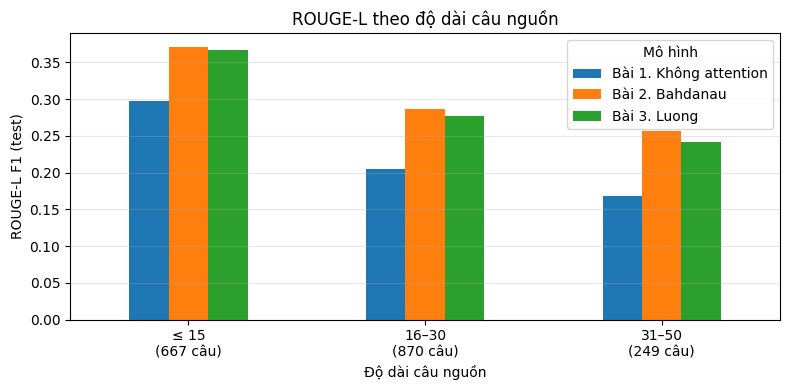

In [32]:
pivot = by_length.pivot(index='Độ dài câu nguồn', columns='Mô hình', values='ROUGE-L F1').loc[bucket_names]
ax = pivot.plot(kind='bar', figsize=(8, 4), rot=0)
counts = by_length.groupby('Độ dài câu nguồn', observed=True)['Số câu'].first().loc[bucket_names]
ax.set_xticklabels([f'{b}\n({c} câu)' for b, c in zip(bucket_names, counts)])
ax.set_ylabel('ROUGE-L F1 (test)')
ax.set_title('ROUGE-L theo độ dài câu nguồn')
ax.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.savefig(ART/'rougeL_by_length.png', dpi=150)
plt.show()

### B. Beam search so với greedy

Beam search giữ $k$ giả thuyết tốt nhất ở mỗi bước thay vì chỉ lấy argmax. Điểm cuối cùng được chuẩn hóa theo độ dài, $\text{score}/\text{lp}(Y)$ với $\text{lp}(Y) = \left(\frac{5+|Y|}{6}\right)^{\alpha}$ (Wu et al., 2016), để không thiên vị câu ngắn. Chọn trước $k=5$, $\alpha=0.6$ và không tinh chỉnh trên test.

In [33]:
@torch.no_grad()
def beam_generate(model, src, lengths, max_steps, k=5, alpha=0.6):
    model.eval()
    B = src.size(0)
    memory, (h, c) = model.encoder(src, lengths)
    mask = src != PAD
    memory, mask = memory.repeat_interleave(k, 0), mask.repeat_interleave(k, 0)
    h, c = h.repeat_interleave(k, 1), c.repeat_interleave(k, 1)
    feeding = memory.new_zeros(B * k, model.hidden)
    token = torch.full((B * k,), BOS, device=src.device)
    scores = torch.full((B, k), float('-inf'), device=src.device)
    scores[:, 0] = 0.0                      # ban đầu chỉ có một giả thuyết
    finished = torch.zeros(B * k, dtype=torch.bool, device=src.device)
    out_len = torch.zeros(B * k, device=src.device)
    seqs = torch.zeros(B * k, 0, dtype=torch.long, device=src.device)
    offset = (torch.arange(B, device=src.device) * k).unsqueeze(1)
    for _ in range(max_steps):
        logits, (h, c), feeding, _ = model.decoder.step(token, (h, c), memory, mask, feeding)
        logp = torch.log_softmax(logits, -1)
        logp[:, [PAD, BOS]] = float('-inf')
        logp[finished] = float('-inf')      # giả thuyết đã xong chỉ được nối EOS, không cộng điểm
        logp[finished, EOS] = 0.0
        V = logp.size(-1)
        cand = (scores.view(-1, 1) + logp).view(B, k * V)
        scores, idx = cand.topk(k, dim=-1)
        parent = (idx // V + offset).view(-1)
        token = (idx % V).view(-1)
        h, c, feeding = h[:, parent], c[:, parent], feeding[parent]
        finished, out_len = finished[parent], out_len[parent] + (~finished[parent]).float()
        seqs = torch.cat([seqs[parent], token.unsqueeze(1)], dim=1)
        finished = finished | (token == EOS)
        if bool(finished.all()):
            break
    lp = ((5 + out_len.view(B, k)) / 6) ** alpha
    best = (scores / lp).argmax(-1)
    return seqs.view(B, k, -1)[torch.arange(B, device=src.device), best]

@torch.no_grad()
def beam_evaluate(model, rows, k=5):
    hyps, refs = [], []
    for b in loader(rows, batch_size=EVAL_BATCH):
        ids = beam_generate(model, b['src'].to(device), b['lengths'], cfg['max_words'] + 1, k=k)
        hyps.extend(decode(r) for r in ids.cpu())
        refs.extend(b['refs'])
    m = translation_metrics(hyps, refs)
    m['hyps'] = hyps
    return m

# Kiểm tra: beam search với k=1 phải trùng với greedy
b = collate(dev_rows[:64])
for n, r in results.items():
    g, _ = generate(r['model'], b['src'].to(device), b['lengths'], cfg['max_words'] + 1)
    bm = beam_generate(r['model'], b['src'].to(device), b['lengths'], cfg['max_words'] + 1, k=1)
    assert [decode(x) for x in g.cpu()] == [decode(x) for x in bm.cpu()]
print('beam k=1 trùng greedy: OK')

beam k=1 trùng greedy: OK


In [34]:
rows = []
for n, r in results.items():
    start = time.perf_counter()
    beam = beam_evaluate(r['model'], test_rows, k=5)
    seconds = time.perf_counter() - start
    r['beam'] = beam
    rows.append({'Mô hình': names[n],
                 'ROUGE-L greedy': round(r['test']['rougeL_f1'], 4),
                 'ROUGE-L beam=5': round(beam['rougeL_f1'], 4),
                 'BLEU greedy': round(r['test']['bleu'], 2),
                 'BLEU beam=5': round(beam['bleu'], 2),
                 'Thời gian beam (s)': round(seconds, 1)})
    pd.DataFrame(dict(id=[x['id'] for x in test_rows], ref=[' '.join(x['tgt']) for x in test_rows],
                      greedy=r['test']['hyps'], beam5=beam['hyps'],
                      rougeL_beam5=beam['per_sentence'])).to_csv(ART/f'test_beam_{n}.csv', index=False)
beam_table = pd.DataFrame(rows)
beam_table.to_csv(ART/'beam_vs_greedy.csv', index=False)
beam_table

,Mô hình,ROUGE-L greedy,ROUGE-L beam=5,BLEU greedy,BLEU beam=5,Thời gian beam (s)
0,Bài 1. Không attention,0.2346,0.2410,2.61,2.84,3.4
1,Bài 2. Bahdanau,0.3138,0.3253,5.83,6.53,3.7
2,Bài 3. Luong,0.3054,0.3177,5.52,6.38,3.0


In [35]:
for i in samples_bahdanau:
    r = test_rows[i]
    print(f"--- Câu test #{r['id']} ---")
    print('REF:', ' '.join(r['tgt']))
    for n, res in results.items():
        print(f"{n:9} greedy: {res['test']['hyps'][i]}")
        print(f"{'':9} beam5 : {res['beam']['hyps'][i]}")
    print()

--- Câu test #822 ---
REF: ( vỗ tay )
none      greedy: ( vỗ tay )
          beam5 : ( vỗ tay )
bahdanau  greedy: ( vỗ tay )
          beam5 : ( vỗ tay )
luong     greedy: ( vỗ tay )
          beam5 : ( vỗ tay )

--- Câu test #1412 ---
REF: nhờ mạng phân phối , các thông tin và dữ liệu lớn có thể làm biến đổi xã hội .
none      greedy: chúng ta có thể có những những những những công nghệ , , , , , và và và và và .
          beam5 : chúng ta có thể có những sự quan trọng trong những công nghệ , , , , những công nghệ của và
bahdanau  greedy: chúng ta đã thấy những công nghệ lớn , , dữ liệu , và dữ liệu có thể tạo ra các hệ thống .
          beam5 : chúng ta đã thấy những công nghệ lớn , công nghệ , dữ liệu dữ liệu có thể thay đổi hệ thống .
luong     greedy: chúng ta đã thấy những cách công nghệ , , công nghệ , công nghệ và công nghệ và có thể công nghệ .
          beam5 : chúng ta đã thấy những công công công nghệ , công nghệ , công nghệ và công nghệ có thể tạo ra công nghệ công nghệ .


### Nhận xét thí nghiệm thêm

**A. Theo độ dài câu.** ROUGE-L của cả ba mô hình đều giảm khi câu nguồn dài hơn. Tuy nhiên mô hình không attention giảm mạnh nhất: từ 0.298 ở câu ≤ 15 từ xuống 0.168 ở câu 31–50 từ (giảm khoảng 43%), trong khi Bahdanau giảm từ 0.371 xuống 0.257 (khoảng 31%). Khoảng cách giữa Bahdanau và không attention tăng từ 0.073 ở câu ngắn lên 0.088 ở câu dài; tính tương đối là +25% ở câu ngắn và +52% ở câu dài. Điều này phù hợp với lập luận rằng attention giảm nút thắt của vector ngữ cảnh cố định, và lợi ích rõ nhất ở câu dài.

**B. Beam search.** Beam search (k = 5) tăng điểm cho cả ba mô hình: ROUGE-L tăng 0.006 (không attention), 0.012 (Bahdanau) và 0.012 (Luong); BLEU tăng từ 2.61 lên 2.84, 5.83 lên 6.53 và 5.52 lên 6.38. Thứ hạng giữa ba mô hình không đổi. Mức tăng này nhỏ hơn nhiều so với khoảng cách 0.07–0.08 giữa có và không có attention, nên kiến trúc ảnh hưởng nhiều hơn cách giải mã. Chi phí thêm không đáng kể: chấm toàn bộ test bằng beam search chỉ mất 3–4 giây trên T4.

Ở các câu mẫu, beam search có lúc chọn từ sát nghĩa hơn: với câu #1412, Bahdanau đổi "tạo ra các hệ thống" thành "có thể thay đổi hệ thống", gần với "transform" hơn. Nhưng lỗi lặp từ vẫn còn ("dữ liệu dữ liệu", Luong vẫn lặp "công nghệ" nhiều lần), và câu #75 vẫn toàn `<unk>`. Beam search chỉ tìm câu có xác suất cao hơn theo chính mô hình, nên không sửa được lỗi do mô hình chưa học tốt hay do từ điển thiếu từ.